exploration, validation and forecasting for the atomity cloud workload challenge (azure vm trace, 10000 machines, 134 readings 5 minutes apart).

part 1: cpu readings and the two targets. part 2: machine metadata (types, sizes, lifetimes). part 3: data quality, validation, models, final forecast, error analysis and recommendation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
cpu = pd.read_csv(r'../challenge_data/vm_cpu_readings.csv.gz')

In [3]:
display(cpu.head())
print(cpu.shape)

,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


(1340000, 5)


In [4]:
print(cpu['timestamp'].nunique())
print(cpu['timestamp'].min())
print(cpu['timestamp'].max())

134
0
39900


all 10000 machines report at the same 134 timestamps


In [5]:
cpu.isna().sum()

timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64

In [6]:
ac_vm_count = cpu['vm_id'].groupby(cpu['timestamp']).nunique()
ac_vm_count.describe()

count      134.0
mean     10000.0
std          0.0
min      10000.0
25%      10000.0
50%      10000.0
75%      10000.0
max      10000.0
Name: vm_id, dtype: float64

the line is constant because of how the data was selected.

only machines with complete 11 hours readings were kept
so the forecast is 10000 for all 24 moments, and the “last value” baseline is already perfect

in real life this number would change as machines start and stop so this target says nothing about real churn

In [7]:
agg_vm_use = cpu['avg_cpu'].groupby(cpu['vm_id']).mean()
agg_vm_use.describe()

count    10000.000000
mean         9.388101
std         13.018681
min          0.007369
25%          2.869113
50%          5.480793
75%          9.934288
max         99.273584
Name: avg_cpu, dtype: float64

most machines are much bigger than they need to be and most of the power sit unused . thats a chance to move them to a smaller or cheaper machines .

for the few busy ones they are at risk of running out of power so they are the ones to watch

In [8]:
avg_per_time = cpu['avg_cpu'].groupby(cpu['timestamp']).mean()
avg_per_time

timestamp
0        9.396898
300      9.353775
600      9.454383
900      9.224419
1200     9.143503
           ...   
38700    9.430236
39000    9.307138
39300    9.499973
39600    9.423042
39900    9.428117
Name: avg_cpu, Length: 134, dtype: float64

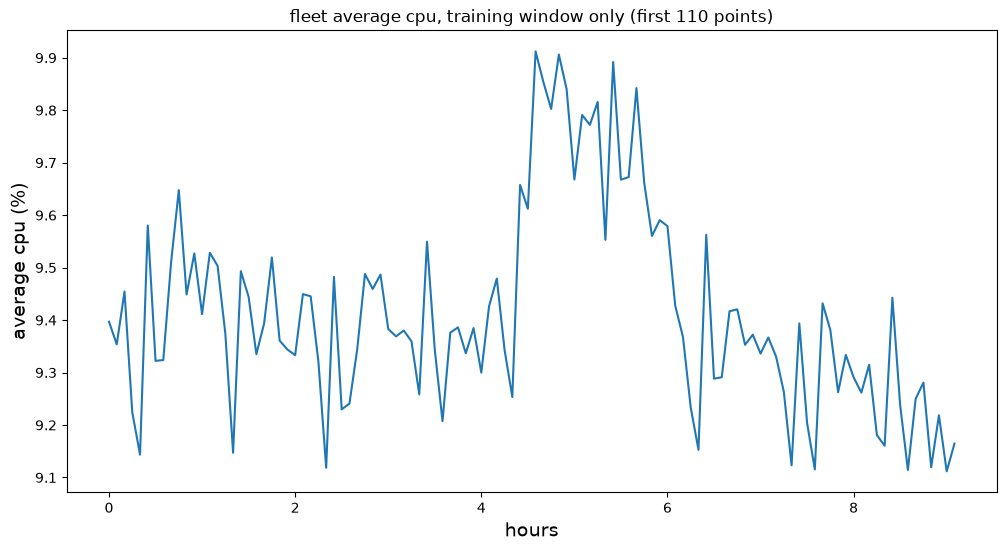

In [9]:
train_only = avg_per_time.iloc[:110]   # the last 24 points (holdout) stay hidden until the end
fig , ax = plt.subplots(figsize=[12,6])
ax.plot((train_only.index/3600),train_only)
plt.title('fleet average cpu, training window only (first 110 points)')
plt.xlabel('hours',size=14)
plt.ylabel('average cpu (%)',size=14)
plt.show()

the fleet average cpu in the training window (first 110 points) stays in a narrow range, between about 9.1% and 9.9%, so the whole fleet is calm and steady.

there is one busy period between about 4.5 and 6 hours where it rises to around 9.8 to 9.9%, then it comes back down. there is no repeating pattern, 11 hours is too short to see a daily cycle.

after moving away from its usual level the line tends to come back toward it (mean reversion), like after the busy period. so copying the last value is not the only reasonable baseline, a baseline using the training average is worth testing too.

the last 24 points (the holdout) are not shown here on purpose. they are only opened once, at the end, after the final method is chosen.

In [10]:
meta = pd.read_csv(r'../challenge_data/vm_metadata.csv.gz')
display(meta.head())
print(meta.shape)

,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4
3,88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...,4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...,yfPM2qpoqC9aXMgM7S0mCLxCY8NEd4C6uiLpfY443SV5Yj...,0,70200,98.738842,81.578650,98.439173,Unknown,4,8
4,C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...,1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...,hrP166UPejKeASJ3ibhQ68YrE7iDxsmlXNZ2B8BBy0BMKn...,0,2591400,90.790129,2.382323,6.902215,Delay-insensitive,2,4


(10000, 11)


In [11]:
meta.columns

Index(['vm_id', 'subscription_id', 'deployment_id', 'timestamp_vm_created',
       'timestamp_vm_deleted', 'max_cpu', 'avg_cpu', 'p95_max_cpu',
       'vm_category', 'virtual_core_bucket', 'memory_gb_bucket'],
      dtype='str')

In [12]:
cat = meta['vm_id'].groupby(meta['vm_category']).nunique()
cat

vm_category
Delay-insensitive    6180
Interactive          3091
Unknown               729
Name: vm_id, dtype: int64

62% of machines are delay insensitive , 31% are interactive , 7% are unknown .

since most machines are delay insensitive, they mostly shape the average cpu line, but interactive ones still play a role.

this matter for capacity because if an interactive machine runs out of cpu a real user feel it right away so it need more headroom.

delay insensitive jobs can wait in a queue, so they can run with less spare capacity and save money.

one safety margin for everyone would waste money on one group or put the other at risk.

In [13]:
cat_use_mean = meta['avg_cpu'].groupby(meta['vm_category']).mean()
print(cat_use_mean)
cat_use_median = meta['avg_cpu'].groupby(meta['vm_category']).median()
print(cat_use_median)

vm_category
Delay-insensitive     8.165126
Interactive          11.435729
Unknown              10.389816
Name: avg_cpu, dtype: float64
vm_category
Delay-insensitive    5.882293
Interactive          6.083141
Unknown              4.033370
Name: avg_cpu, dtype: float64


at first glance the mean of every category show that the interactive ones are the busiest.
i used the median because it doesnt get affected by extreme values and it shows that the delay insensitive and interactive are busy nearly the same .
but the unknown and interactive show a big gap between mean and median which suggest that most of the machines are calm but few are extremely busy.

that suggest that the focus should be on some hot machines that have high usage

these numbers use the lifetime avg_cpu from the metadata, which covers each machine’s whole life, not only our 11 hours, so i use them to describe groups, not to forecast

In [14]:
buckets = meta['vm_id'].groupby(meta['virtual_core_bucket']).nunique()
buckets

virtual_core_bucket
2      7534
24       62
4      1908
8       486
>24      10
Name: vm_id, dtype: int64

In [15]:
print(meta['avg_cpu'].groupby(meta['virtual_core_bucket']).mean())
print(meta['avg_cpu'].groupby(meta['virtual_core_bucket']).median())

virtual_core_bucket
2       9.503154
24     11.692486
4       8.446552
8      10.024329
>24     7.295182
Name: avg_cpu, dtype: float64
virtual_core_bucket
2      6.268932
24     8.701582
4      3.653585
8      5.465242
>24    4.730607
Name: avg_cpu, dtype: float64


In [16]:
bucket_max = meta['p95_max_cpu'].groupby(meta['virtual_core_bucket'])
print(bucket_max.mean())
print(bucket_max.median())

virtual_core_bucket
2      36.590480
24     38.301577
4      33.997612
8      41.503538
>24    56.777894
Name: p95_max_cpu, dtype: float64
virtual_core_bucket
2      22.388684
24     34.071727
4      25.110267
8      36.634293
>24    67.607207
Name: p95_max_cpu, dtype: float64


there is no clear pattern that bigger bucket mean more usage .

peaks are 5 to 7 time the average so sizing must use peaks.

an 8 core bucket could be downsized to 4 core bucket because the peak of 8 core ones are about 37% (37% of 8 cores ≈ 2.9 cores, about 73% of a 4 core) so a 4 core will be enough with a spare headroom.
a 2 core will choke because it will be 146% of its capacity .

buckets are ranges so the core math is approximate .

the 24 , >24 groups are too small (62,10) to trust .

these are lifetime stats from metadata.



In [17]:

meta['lifetime_hours'] = ((meta['timestamp_vm_deleted']-meta['timestamp_vm_created'])/3600)
display(meta['lifetime_hours'].head())
print(meta['lifetime_hours'].describe())

0    719.833333
1    112.833333
2    719.833333
3     19.500000
4    719.833333
Name: lifetime_hours, dtype: float64

count    10000.000000
mean       636.007117
std        196.694676
min         11.250000
25%        719.833333
50%        719.833333
75%        719.833333
max        719.833333
Name: lifetime_hours, dtype: float64


more than 75% of machines ran the whole month .

the min is about 11 hour because of the selection filter. machines with a reading at all 134 timestamps (the whole 11 hour window) were kept, so no machine shorter than that can appear

the 10000 machine count is flat because the filter not because real fleet are that stable so our results describe long running machines only

In [18]:
train_cpu = avg_per_time[0:110]
train_cpu.index.max()

np.int64(32700)

In [19]:
print(train_cpu.loc[train_cpu== train_cpu.max()])

timestamp
16500    9.912175
Name: avg_cpu, dtype: float64


In [20]:
print(16500/3600)

4.583333333333333


In [21]:

print(train_cpu.loc[train_cpu== train_cpu.min()])

timestamp
32400    9.111634
Name: avg_cpu, dtype: float64


In [22]:
print(32400/3600)


9.0


peak was 9.9% at hour 4.6 and low was 9.1% at hour 9.

the low sits one step before the end of training, right before the split.

the training range is small, from 9.1% to 9.9%, about 0.8 percentage points.

because training ends near its lowest point, the last value baseline will likely be too low if the line goes back up (mean reversion). too low means the team prepares less cpu than needed, which is under provisioning, the dangerous side.


there is no repeating pattern in the 11 hour. just 1 busy period and a dip.

a daily cycle cant be seen with only 11 hours,so seasonal naive with a daily season isnt possible .

LIMITATION : a real forecast would need days or weeks of data to catch daily and weekly cycle .

In [23]:
cpu[['timestamp','vm_id']].duplicated().sum()


np.int64(0)

In [24]:

ts = pd.Series(avg_per_time.index)
gaps = ts.diff()
print(gaps.value_counts())
print("number of timestamps:", len(ts))
print("all gaps are 300:", (gaps.dropna() == 300).all())

timestamp
300.0    133
Name: count, dtype: int64
number of timestamps: 134
all gaps are 300: True


In [25]:
print(cpu[['min_cpu', 'avg_cpu', 'max_cpu']].describe())
cols = ['min_cpu', 'avg_cpu', 'max_cpu']
print("all >= 0:", (cpu[cols] >= 0).all().all())
print("all <= 100:", (cpu[cols] <= 100).all().all())
ok = (cpu['min_cpu'] <= cpu['avg_cpu']) & (cpu['avg_cpu'] <= cpu['max_cpu'])
print("rows where min <= avg <= max:", ok.sum(), "of", len(cpu))

            min_cpu       avg_cpu       max_cpu
count  1.340000e+06  1.340000e+06  1.340000e+06
mean   6.156478e+00  9.388101e+00  1.834830e+01
std    1.175525e+01  1.426601e+01  2.161651e+01
min    0.000000e+00  7.158922e-03  1.810795e-02
25%    1.487979e+00  2.477060e+00  4.417642e+00
50%    3.227996e+00  5.105133e+00  9.124204e+00
75%    5.331087e+00  9.616715e+00  2.362418e+01
max    9.928158e+01  9.948803e+01  9.970286e+01
all >= 0: True
all <= 100: True
rows where min <= avg <= max: 1340000 of 1340000


data quality :

no duplicate (machine, timestamp) pairs

all 133 gaps are exactly 300 seconds, so no holes in time

all cpu values are between 0 and 100, and min ≤ avg ≤ max in every row

so no cleaning, filling or resampling was needed. if readings were missing they would be ignored, not filled in.

inside 5 minutes, max cpu is about 2x the average, so spikes are short and hidden by averages.

In [26]:
from cwfc.metrics import mae, rmse
import numpy as np

origins = [50, 62, 74, 86]
horizon = 24
rounds = []
for i in origins:
    train = train_cpu.iloc[:i]
    test = train_cpu.iloc[i:i + horizon]
    rounds.append((train, test))
    print(f"origin {i}: train {len(train)}, test {len(test)}, test from {test.index[0]} to {test.index[-1]}")

def last_value(train, n):
    return np.repeat(train.iloc[-1], n)

def train_mean(train, n):
    return np.repeat(train.mean(), n)

def moving_avg(train, n, window=12):
    return np.repeat(train.iloc[-window:].mean(), n)

baselines = {"last value": last_value, "train mean": train_mean, "moving avg 1h": moving_avg}

results = []
for origin, (train, test) in zip(origins, rounds):
    for name, fn in baselines.items():
        pred = fn(train, len(test))
        results.append({"origin": origin, "baseline": name,
                        "mae": mae(test, pred), "rmse": rmse(test, pred),
                        "bias": (pred - test.values).mean()})

results = pd.DataFrame(results)
print(results.round(3))
print()
print(results.groupby("baseline")[["mae", "rmse", "bias"]].mean().sort_values("mae").round(3))

origin 50: train 50, test 24, test from 15000 to 21900
origin 62: train 62, test 24, test from 18600 to 25500
origin 74: train 74, test 24, test from 22200 to 29100
origin 86: train 86, test 24, test from 25800 to 32700
    origin       baseline    mae   rmse   bias
0       50     last value  0.268  0.303 -0.247
1       50     train mean  0.303  0.337 -0.288
2       50  moving avg 1h  0.324  0.360 -0.314
3       62     last value  0.297  0.346  0.283
4       62     train mean  0.173  0.210 -0.067
5       62  moving avg 1h  0.220  0.261  0.168
6       74     last value  0.124  0.152  0.113
7       74     train mean  0.171  0.193  0.164
8       74  moving avg 1h  0.355  0.369  0.355
9       86     last value  0.132  0.154  0.117
10      86     train mean  0.210  0.233  0.210
11      86  moving avg 1h  0.119  0.140  0.097

                 mae   rmse   bias
baseline                          
last value     0.206  0.239  0.067
train mean     0.214  0.243  0.005
moving avg 1h  0.254  0.282 

validation: rolling origin inside the first 110 points only, 4 rounds starting at points 50, 62, 74, 86, each forecasting the next 24 points (2 hours, same as the real task). training always uses only the past. the real holdout (last 24) is never touched.

i did not use the starter rolling_origin_splits as is, because its defaults (1 week of training, 1 day horizon) do not fit 134 points and would give zero rounds.

results (average of 4 rounds):
last value  mae 0.206  rmse 0.239
train mean  mae 0.214  rmse 0.243
moving avg  mae 0.254  rmse 0.282

last value and train mean are basically tied, the best one changes from round to round. errors are about 0.2 points on a level of about 9.4%, so around 2%. the line is very predictable with simple rules. the model has to beat last value (mae 0.206) to be worth using.

seasonal naive was not tested because 11 hours cannot contain a daily cycle.

In [27]:
from sklearn.linear_model import Ridge

LAGS = [1, 2, 3, 6, 12]

def make_features(s):
    df = pd.DataFrame({"y": s.values})
    for lag in LAGS:
        df[f"lag{lag}"] = df["y"].shift(lag)
    df["roll12"] = df["y"].shift(1).rolling(12).mean()
    return df.dropna()

def ridge_lags(train, n):
    feats = make_features(train)
    X, y = feats.drop(columns="y"), feats["y"]
    model = Ridge(alpha=1.0).fit(X, y)
    history = list(train.values)
    preds = []
    for _ in range(n):
        h = pd.Series(history)
        row = {f"lag{lag}": h.iloc[-lag] for lag in LAGS}
        row["roll12"] = h.iloc[-12:].mean()
        p = model.predict(pd.DataFrame([row])[X.columns])[0]
        preds.append(p)
        history.append(p)
    return np.array(preds)

def blend(train, n):
    return (last_value(train, n) + train_mean(train, n)) / 2

methods = {"last value": last_value, "train mean": train_mean,
           "moving avg 1h": moving_avg, "ridge lags": ridge_lags,
           "blend": blend}

results = []
for origin, (train, test) in zip(origins, rounds):
    for name, fn in methods.items():
        pred = fn(train, len(test))
        results.append({"origin": origin, "method": name,
                        "mae": mae(test, pred), "rmse": rmse(test, pred),
                        "bias": (pred - test.values).mean()})

results = pd.DataFrame(results)
print(results.round(3))
print()
print(results.groupby("method")[["mae", "rmse", "bias"]].mean().sort_values("mae").round(3))

    origin         method    mae   rmse   bias
0       50     last value  0.268  0.303 -0.247
1       50     train mean  0.303  0.337 -0.288
2       50  moving avg 1h  0.324  0.360 -0.314
3       50     ridge lags  0.312  0.349 -0.302
4       50          blend  0.285  0.320 -0.267
5       62     last value  0.297  0.346  0.283
6       62     train mean  0.173  0.210 -0.067
7       62  moving avg 1h  0.220  0.261  0.168
8       62     ridge lags  0.259  0.302  0.212
9       62          blend  0.192  0.226  0.108
10      74     last value  0.124  0.152  0.113
11      74     train mean  0.171  0.193  0.164
12      74  moving avg 1h  0.355  0.369  0.355
13      74     ridge lags  0.251  0.267  0.251
14      74          blend  0.147  0.172  0.138
15      86     last value  0.132  0.154  0.117
16      86     train mean  0.210  0.233  0.210
17      86  moving avg 1h  0.119  0.140  0.097
18      86     ridge lags  0.165  0.192  0.161
19      86          blend  0.168  0.192  0.164

            

ridge regression on lag features (cpu 5, 10, 15, 30 and 60 minutes ago, plus the average of the last hour). it forecasts 24 steps recursively, each step uses the previous prediction as the newest lag. tested on the same 4 practice exams as the baselines.

results (average of 4 exams):
last value     mae 0.206  rmse 0.239  bias +0.067
train mean     mae 0.214  rmse 0.243  bias +0.005
ridge lags     mae 0.247  rmse 0.278  bias +0.081
moving avg 1h  mae 0.254  rmse 0.282  bias +0.077

ridge did not beat the simple baselines. why:
1. very little data to learn from (38 to 74 rows per exam).
2. the line moves inside about 0.8 percentage points with no repeating pattern, so the recent past says little about the next move.
3. recursive forecasting stacks errors, each of the 24 steps builds on the previous guess.
4. it leans high (bias +0.081), so it over forecasts.

this is a finding, not a failure: at this scale the workload is close to its own recent level, and simple rules are hard to beat. alpha and lags were not tuned, because tuning on 4 small exams would just chase noise.

blend = average of last value and train mean. idea: start from the current level but expect a pull back toward the normal level (mean reversion seen in exploration). last value and train mean win on different exams, so averaging cancels part of both mistakes.

results (average of 4 exams):
blend          mae 0.198  rmse 0.228  bias +0.036
last value     mae 0.206  rmse 0.239  bias +0.067
train mean     mae 0.214  rmse 0.243  bias +0.005
ridge lags     mae 0.247  rmse 0.278  bias +0.081
moving avg 1h  mae 0.254  rmse 0.282  bias +0.077

blend is best on mae and rmse, about 4% better than last value (normalized mae 0.96). the gain is small, but blend is the most consistent: never the worst in any exam. its small positive bias means it leans slightly high, the safer side for capacity.

final method: blend. no more methods tested after this, to avoid picking something that only got lucky on 4 small exams.

In [28]:
# how predictable is the line? training window only
s = train_cpu.reset_index(drop=True)
changes = s.diff().dropna()
print("correlation between one value and the next:", round(s.autocorr(1), 3))
print("typical 5 minute move (std of changes):", round(changes.std(), 3))
print("correlation between one move and the next:", round(changes.autocorr(1), 3))

# a flat forecast that knows the exact average of each exam window (impossible in practice)
oracle = [np.abs(test.values - test.values.mean()).mean() for _, test in rounds]
print("best possible flat forecast mae (knows the future average):", round(np.mean(oracle), 3))
print("blend mae in validation:", round(results.loc[results["method"] == "blend", "mae"].mean(), 3))

correlation between one value and the next: 0.667
typical 5 minute move (std of changes): 0.158
correlation between one move and the next: -0.415
best possible flat forecast mae (knows the future average): 0.12
blend mae in validation: 0.198


how predictable is it:

every 5 minutes the line moves by about 0.16 points, and each move tends to reverse the next step (correlation between one move and the next about -0.42). so it is a zigzag around a level, not a trend you can follow. that is why ridge, which tries to follow the moves, did worse.

even a flat forecast that knows the exact future average of each exam window (impossible in practice) would get mae 0.12. the blend gets 0.198. so the level is predictable within about 2%, and the 5 minute moves are mostly noise. a flat forecast at the right level plus a safety margin is the right tool here.

holdout points: 24 from 33000 to 39900
          method    mae   rmse   bias
3     ridge lags  0.106  0.142 -0.035
2  moving avg 1h  0.123  0.161 -0.053
4          blend  0.124  0.154  0.020
0     last value  0.147  0.185 -0.104
1     train mean  0.175  0.210  0.145
blend forecast value: 9.289
normalized mae (blend / last value): 0.848
active vm forecast: 10000 | real holdout values: [10000]


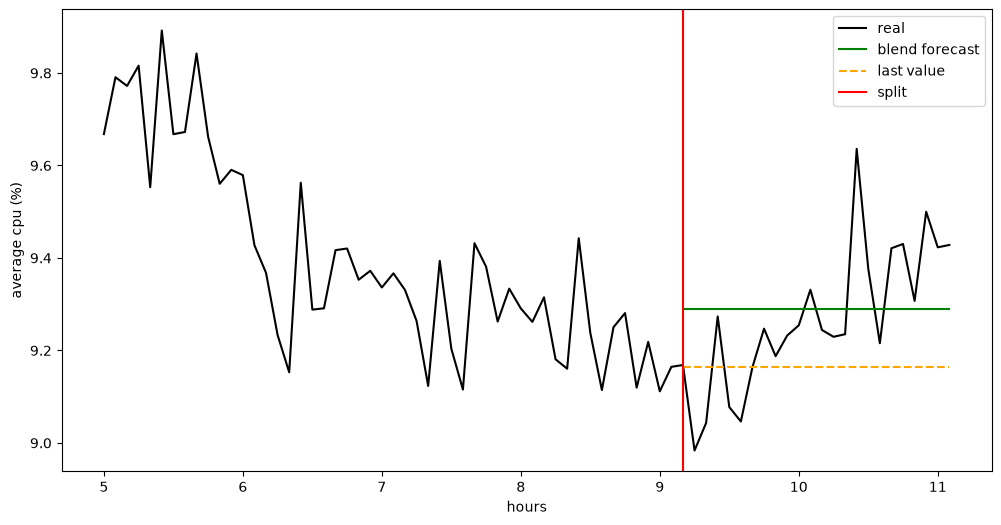

In [29]:
import matplotlib.pyplot as plt

holdout = avg_per_time.iloc[110:]
print("holdout points:", len(holdout), "from", holdout.index[0], "to", holdout.index[-1])

final_preds = {name: fn(train_cpu, len(holdout)) for name, fn in methods.items()}

rows = []
for name, pred in final_preds.items():
    rows.append({"method": name,
                 "mae": mae(holdout, pred),
                 "rmse": rmse(holdout, pred),
                 "bias": (pred - holdout.values).mean()})
holdout_scores = pd.DataFrame(rows).sort_values("mae")
print(holdout_scores.round(3))

blend_pred = final_preds["blend"]
print("blend forecast value:", round(blend_pred[0], 3))
print("normalized mae (blend / last value):",
      round(mae(holdout, blend_pred) / mae(holdout, final_preds["last value"]), 3))

# active vm count: last value forecast
vm_pred = ac_vm_count.iloc[109]
print("active vm forecast:", vm_pred, "| real holdout values:", ac_vm_count.iloc[110:].unique())

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(avg_per_time.index[60:] / 3600, avg_per_time.iloc[60:], label="real", color="black")
ax.plot(holdout.index / 3600, blend_pred, label="blend forecast", color="green")
ax.plot(holdout.index / 3600, final_preds["last value"], label="last value", color="orange", linestyle="--")
ax.axvline(x=110 * 300 / 3600, color="red", label="split")
ax.set_xlabel("hours")
ax.set_ylabel("average cpu (%)")
ax.legend()
plt.show()

final forecast: blend trained on all 110 points, forecast = 9.29% for all 24 holdout points. choice was locked before looking at the holdout.

holdout results:

ridge lags     mae 0.106  rmse 0.142  bias -0.035

moving avg 1h  mae 0.123  rmse 0.161  bias -0.053

blend          mae 0.124  rmse 0.154  bias +0.020

last value     mae 0.147  rmse 0.185  bias -0.104

train mean     mae 0.175  rmse 0.210  bias +0.145

blend beats the last value baseline by about 15% (normalized mae 0.848) and is almost unbiased.
last value is too low (bias -0.104), as expected from exploration: training ended near its lowest point, so repeating the last value under provisions.
ridge scored best on this one window but lost on all 4 practice exams. one 2 hour window is not enough to change the choice, so the blend stays the final method.
active vm count forecast is 10000, exactly right at every point (constant because of the selection filter).

In [30]:
err = blend_pred - holdout.values
ea = pd.DataFrame({"hour": holdout.index / 3600,
                   "real": holdout.values,
                   "forecast": blend_pred,
                   "error": err})

peak_thr = train_cpu.quantile(0.75)
ea["high_load"] = ea["real"] > peak_thr
ea["part"] = np.where(np.arange(len(ea)) < 12, "first hour", "second hour")

print(ea.round(3))
print("\nhigh load threshold (75th pct of training):", round(peak_thr, 3))

def summarize(g):
    return pd.Series({"points": len(g),
                      "mae": g["error"].abs().mean(),
                      "bias": g["error"].mean(),
                      "worst under": g["error"].min()})

print("\nby hour:")
print(ea.groupby("part").apply(summarize).round(3))
print("\nby load:")
print(ea.groupby("high_load").apply(summarize).round(3))

worst = ea.loc[ea["error"].idxmin()]
print("worst under forecast:", round(worst["error"], 3), "at hour", round(worst["hour"], 2), "real", round(worst["real"], 3))

      hour   real  forecast  error  high_load         part
0    9.167  9.168     9.289  0.121      False   first hour
1    9.250  8.984     9.289  0.306      False   first hour
2    9.333  9.043     9.289  0.246      False   first hour
3    9.417  9.274     9.289  0.016      False   first hour
4    9.500  9.078     9.289  0.212      False   first hour
5    9.583  9.046     9.289  0.243      False   first hour
6    9.667  9.164     9.289  0.125      False   first hour
7    9.750  9.247     9.289  0.042      False   first hour
8    9.833  9.188     9.289  0.102      False   first hour
9    9.917  9.232     9.289  0.057      False   first hour
10  10.000  9.254     9.289  0.035      False   first hour
11  10.083  9.331     9.289 -0.042      False   first hour
12  10.167  9.244     9.289  0.045      False  second hour
13  10.250  9.229     9.289  0.060      False  second hour
14  10.333  9.235     9.289  0.054      False  second hour
15  10.417  9.636     9.289 -0.347       True  second ho

error analysis (error = forecast minus real, negative = too low = under provisioning):

first hour: mae 0.129, bias +0.122. the real line dipped to about 9.0 right after the split, the blend (9.29) was too high. safe side, wasted capacity.
second hour: mae 0.120, bias -0.081. the line climbed back to 9.4 to 9.6, the blend was too low. risky side.
the error did not grow with the horizon. the failure is the shape: a flat forecast cannot follow a dip followed by a recovery.

high load (above 9.508, the 75th percentile of training): only 1 holdout point, a short spike to 9.636 at hour 10.42. the blend missed it by 0.347 (about 3.7% of the level), its worst miss. one point is not enough to judge peak performance, but it confirms what exploration showed: short spikes are hidden by averages and a flat forecast will miss them.

failure modes:
1. cannot follow up and down moves inside the 2 hours.
2. misses short spikes.
these are why the recommendation adds a safety margin on top of the forecast.

validation misses: 96
   level  margin (points)  margin % of forecast  holdout covered %  \
0   0.80            0.185                 1.991             91.667   
1   0.90            0.321                 3.457             95.833   
2   0.95            0.435                 4.682            100.000   
3   1.00            0.507                 5.453            100.000   

   avg spare (points)  
0               0.205  
1               0.341  
2               0.455  
3               0.527  


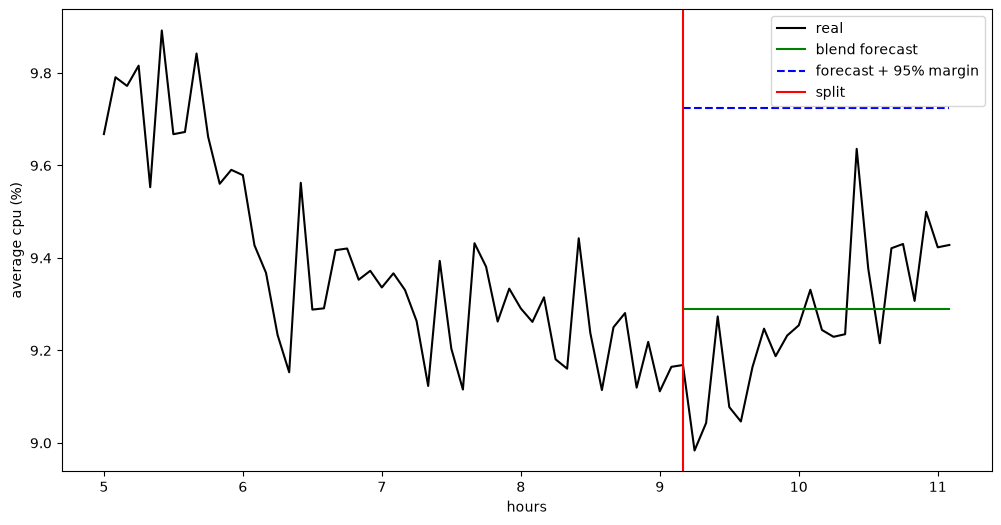

In [31]:
val_miss = []
for train, test in rounds:
    pred = blend(train, len(test))
    val_miss.extend(test.values - pred)
val_miss = np.array(val_miss)
print("validation misses:", len(val_miss))

rows = []
for level in [0.80, 0.90, 0.95, 1.00]:
    margin = np.quantile(val_miss, level)
    upper = blend_pred + margin
    rows.append({"level": level,
                 "margin (points)": margin,
                 "margin % of forecast": 100 * margin / blend_pred[0],
                 "holdout covered %": 100 * (holdout.values <= upper).mean(),
                 "avg spare (points)": (upper - holdout.values).mean()})
policy = pd.DataFrame(rows)
print(policy.round(3))

m95 = np.quantile(val_miss, 0.95)
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(avg_per_time.index[60:] / 3600, avg_per_time.iloc[60:], label="real", color="black")
ax.plot(holdout.index / 3600, blend_pred, label="blend forecast", color="green")
ax.plot(holdout.index / 3600, blend_pred + m95, label="forecast + 95% margin", color="blue", linestyle="--")
ax.axvline(x=110 * 300 / 3600, color="red", label="split")
ax.set_xlabel("hours")
ax.set_ylabel("average cpu (%)")
ax.legend()
plt.show()

recommendation for the infrastructure team:

1. fleet level: plan capacity at forecast + 4.7% (the 95th percentile of the blend's misses in the practice exams, chosen before looking at the holdout). on the holdout this covered all 24 points, including the spike at hour 10.4, at the cost of about 0.46 points of unused capacity on average.

2. trade off: a 90% margin (+3.5%) is cheaper and covered 23 of 24 points, only missing the short spike. under provisioning means slow services and unhappy users, over provisioning means paying for idle machines. the 95% policy accepts a small extra cost to avoid running short.

3. segment rule: use the 95% margin for interactive machines, where a user feels a shortage right away. delay insensitive jobs can queue, so the 90% margin is enough for them and saves money.

4. single machines: this margin is for the fleet average. individual machines spike much harder: within 5 minutes max cpu is about 2x the average, and over their lifetime the p95 peak is 5 to 7x the average. size single machines on their peaks, not on this forecast. for example a typical 8 core machine peaks at about 2.9 cores, so 4 cores is enough, 2 cores is not.

5. operations: refresh the forecast every 5 to 15 minutes with the newest data, and trigger a scale up if real usage crosses the forecast + margin line.

caveats: the margin comes from 96 practice misses in one 11 hour window, it should be recalculated with more data. the target is the average of percentages, not total cores, and the fleet only contains long running machines (selection filter).